# Bonus — Trader Behavioral Archetypes (Clustering)

**Goal:** Discover natural trader behavioral archetypes using unsupervised clustering.

Features used:
- Trading intensity (avg trades/day, total volume)
- Position sizing (avg trade size)
- Win rate
- Long/short directional bias
- PnL consistency (Sharpe proxy)
- Sentiment sensitivity (how behavior changes with fear vs greed)

Methods:
1. **K-Means** — primary clustering (with elbow + silhouette selection)
2. **PCA** — 2D visualization of clusters
3. **Radar chart** — archetype profile comparison

## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples
from scipy.spatial.distance import cdist

plt.rcParams.update({
    'figure.facecolor': '#0f1117',
    'axes.facecolor':   '#1a1d2e',
    'axes.edgecolor':   '#3a3d52',
    'axes.labelcolor':  '#e0e0e0',
    'xtick.color':      '#a0a0b0',
    'ytick.color':      '#a0a0b0',
    'text.color':       '#e0e0e0',
    'grid.color':       '#2a2d3e',
    'grid.alpha':       0.5,
    'font.family':      'DejaVu Sans',
    'font.size':        11,
    'axes.titlesize':   13,
    'axes.titleweight': 'bold',
    'figure.dpi':       130,
})

CHARTS_DIR = Path('../charts')
CHARTS_DIR.mkdir(exist_ok=True)

def save(name):
    plt.savefig(CHARTS_DIR / f'{name}.png', bbox_inches='tight',
                facecolor=plt.rcParams['figure.facecolor'])
    plt.show()
    print(f'  ✔ saved → charts/{name}.png')

CLUSTER_COLORS = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12', '#9b59b6']

print('✅ Setup complete')

✅ Setup complete


## 1. Load & Build Trader-Level Feature Matrix

In [2]:
# ── Load raw data ─────────────────────────────────────────────────────────────
fg = pd.read_csv('../data/fear_greed_index.csv')
hl = pd.read_csv('../data/historical_data.csv')

# ── Prep ──────────────────────────────────────────────────────────────────────
fg['date'] = pd.to_datetime(fg['timestamp'], unit='s').dt.normalize()
fg = fg.sort_values('date').drop_duplicates('date', keep='last')
SENT_ORDER = ['Extreme Fear', 'Fear', 'Neutral', 'Greed', 'Extreme Greed']
fg['sentiment_score'] = pd.Categorical(fg['classification'],
                                        categories=SENT_ORDER, ordered=True).codes

hl['date']     = pd.to_datetime(hl['Timestamp IST'], dayfirst=True).dt.normalize()
hl['is_long']  = (hl['Direction'].str.strip().str.lower() == 'buy').astype(int)
hl['is_win']   = (hl['Closed PnL'] > 0).astype(int)
hl['is_close'] = (hl['Closed PnL'] != 0).astype(int)

daily = (
    hl.groupby(['Account', 'date'])
    .agg(
        daily_pnl        = ('Closed PnL',  'sum'),
        trade_count      = ('Trade ID',    'count'),
        avg_size_usd     = ('Size USD',    'mean'),
        total_volume_usd = ('Size USD',    'sum'),
        wins             = ('is_win',      'sum'),
        closes           = ('is_close',    'sum'),
        long_trades      = ('is_long',     'sum'),
        total_fee        = ('Fee',         'sum'),
    )
    .reset_index()
)
daily['win_rate']      = np.where(daily['closes'] > 0, daily['wins'] / daily['closes'], np.nan)
daily['long_ratio']    = daily['long_trades'] / daily['trade_count']
daily['pnl_positive']  = (daily['daily_pnl'] > 0).astype(int)
daily = daily.merge(fg[['date', 'value', 'classification', 'sentiment_score']],
                    on='date', how='inner')

print(f'Daily rows: {len(daily):,} | Unique traders: {daily.Account.nunique()}')

Daily rows: 2,340 | Unique traders: 32


In [3]:
# ── Build per-trader summary ──────────────────────────────────────────────────
trader_stats = (
    daily.groupby('Account')
    .agg(
        total_pnl           = ('daily_pnl',       'sum'),
        avg_daily_pnl       = ('daily_pnl',       'mean'),
        pnl_std             = ('daily_pnl',       'std'),
        total_trades        = ('trade_count',     'sum'),
        trading_days        = ('date',            'nunique'),
        avg_size_usd        = ('avg_size_usd',    'mean'),
        mean_win_rate       = ('win_rate',        'mean'),
        mean_long_ratio     = ('long_ratio',      'mean'),
        mean_volume_per_day = ('total_volume_usd','mean'),
    )
    .reset_index()
)
trader_stats['avg_trades_per_day'] = trader_stats['total_trades'] / trader_stats['trading_days']
trader_stats['sharpe_proxy']       = trader_stats['avg_daily_pnl'] / (trader_stats['pnl_std'] + 1e-9)

# ── Sentiment sensitivity: win rate change between fear vs greed regimes ─────
fear_days  = daily[daily['classification'].isin(['Extreme Fear', 'Fear'])]
greed_days = daily[daily['classification'].isin(['Greed', 'Extreme Greed'])]

wr_fear  = fear_days.groupby('Account')['win_rate'].mean().rename('wr_fear')
wr_greed = greed_days.groupby('Account')['win_rate'].mean().rename('wr_greed')
tc_fear  = fear_days.groupby('Account')['trade_count'].mean().rename('tc_fear')
tc_greed = greed_days.groupby('Account')['trade_count'].mean().rename('tc_greed')

trader_stats = trader_stats.join(wr_fear, on='Account')
trader_stats = trader_stats.join(wr_greed, on='Account')
trader_stats = trader_stats.join(tc_fear, on='Account')
trader_stats = trader_stats.join(tc_greed, on='Account')

trader_stats['wr_sentiment_delta']  = trader_stats['wr_greed'] - trader_stats['wr_fear']
trader_stats['tc_sentiment_delta']  = trader_stats['tc_greed'] - trader_stats['tc_fear']

print(f'Traders with full stats: {len(trader_stats)}')
trader_stats.head(3)

Traders with full stats: 32


,Account,total_pnl,avg_daily_pnl,pnl_std,total_trades,trading_days,avg_size_usd,mean_win_rate,mean_long_ratio,mean_volume_per_day,avg_trades_per_day,sharpe_proxy,wr_fear,wr_greed,tc_fear,tc_greed,wr_sentiment_delta,tc_sentiment_delta
0,0x083384f897ee0f19899168e3b1bec365f52a9012,1.600230e+06,66676.242499,150401.797346,3818,24,33569.102224,0.770691,0.00000,2.570719e+06,159.083333,0.443321,0.955718,0.494138,268.285714,126.583333,-0.461580,-141.702381
1,0x23e7a7f8d14b550961925fbfdaa92f5d195ba5bd,4.788532e+04,920.871548,3603.042291,7280,52,4359.830930,0.774669,0.38334,2.314517e+05,140.000000,0.255582,0.668928,0.904115,139.600000,139.555556,0.235187,-0.044444
2,0x271b280974205ca63b716753467d5a371de622ab,-7.043619e+04,-5869.682610,33420.410014,3809,12,11057.118419,0.729190,0.00000,2.822787e+06,317.416667,-0.175632,0.959715,0.805630,533.000000,109.000000,-0.154085,-424.000000


## 2. Optimal K — Elbow + Silhouette

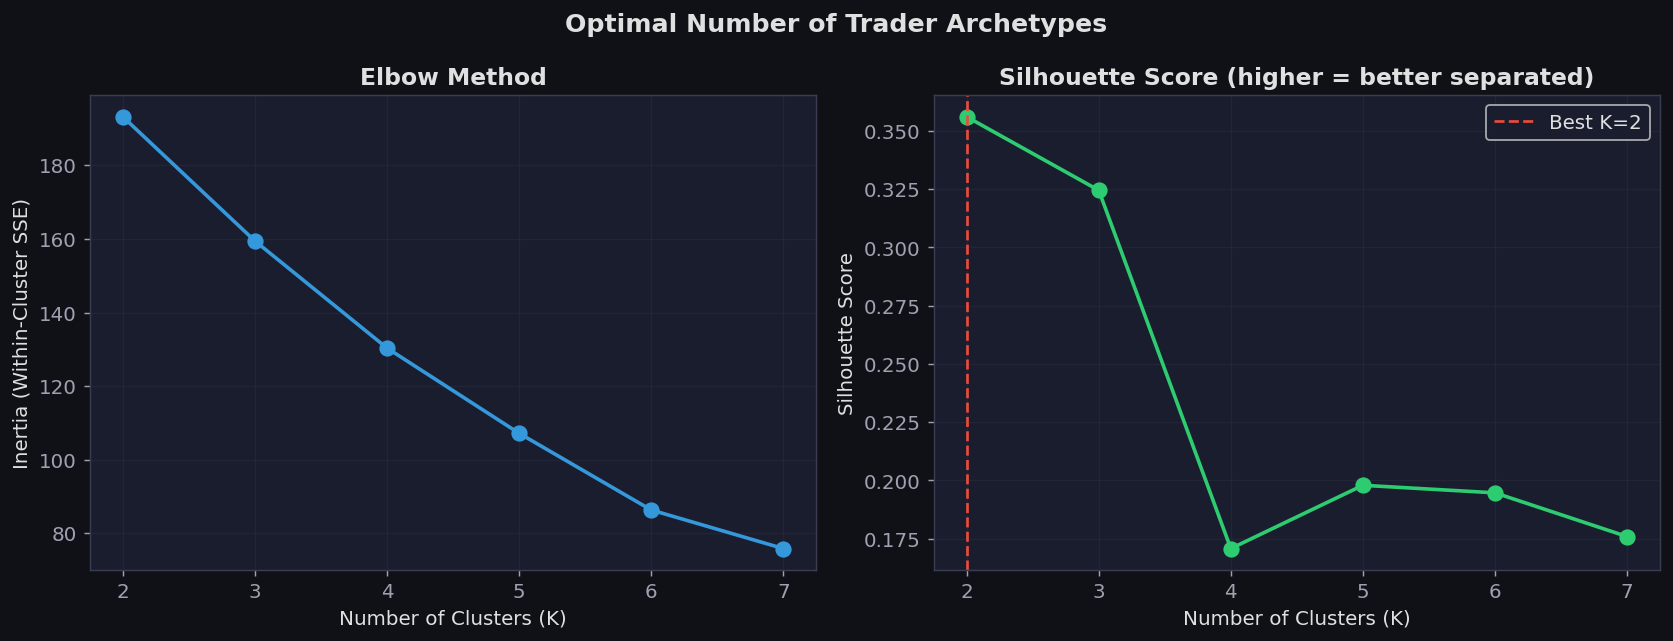

  ✔ saved → charts/bonus_cluster_k_selection.png
  → Best K by silhouette: 2


In [4]:
# ── Clustering features ───────────────────────────────────────────────────────
CLUSTER_FEATURES = [
    'avg_trades_per_day',
    'avg_size_usd',
    'mean_win_rate',
    'mean_long_ratio',
    'sharpe_proxy',
    'mean_volume_per_day',
    'wr_sentiment_delta',
    'tc_sentiment_delta',
]

X_cluster = trader_stats[CLUSTER_FEATURES].fillna(0)
scaler    = StandardScaler()
X_scaled  = scaler.fit_transform(X_cluster)

# ── Elbow + Silhouette ────────────────────────────────────────────────────────
K_range    = range(2, min(len(trader_stats), 8))
inertias   = []
sil_scores = []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.plot(list(K_range), inertias, 'o-', color='#3498db', linewidth=2, markersize=8)
ax.set_xlabel('Number of Clusters (K)')
ax.set_ylabel('Inertia (Within-Cluster SSE)')
ax.set_title('Elbow Method')
ax.grid(True)

ax2 = axes[1]
ax2.plot(list(K_range), sil_scores, 'o-', color='#2ecc71', linewidth=2, markersize=8)
best_k = list(K_range)[np.argmax(sil_scores)]
ax2.axvline(best_k, color='#e74c3c', linestyle='--', label=f'Best K={best_k}')
ax2.set_xlabel('Number of Clusters (K)')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Score (higher = better separated)')
ax2.legend()
ax2.grid(True)

plt.suptitle('Optimal Number of Trader Archetypes', fontsize=14, fontweight='bold')
plt.tight_layout()
save('bonus_cluster_k_selection')
print(f'  → Best K by silhouette: {best_k}')

## 3. Final Clustering & Archetype Profiles

In [11]:
# ── Fit final K-Means ─────────────────────────────────────────────────────────
N_CLUSTERS = best_k  # or override: N_CLUSTERS = 4
km_final   = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=50)
trader_stats['cluster'] = km_final.fit_predict(X_scaled)

# ── Cluster profiles (normalized 0–1 for radar chart) ────────────────────────
cluster_profiles = (
    trader_stats.groupby('cluster')[CLUSTER_FEATURES + ['total_pnl', 'trading_days']]
    .mean()
    .round(3)
)

print('=== Cluster Profiles (raw means) ===')
print(cluster_profiles.to_string())

# ── Assign archetype names based on profile ───────────────────────────────────
# Rank clusters by sharpe proxy and avg_trades_per_day to auto-label
archetype_labels_map = {}
sorted_by_sharpe = cluster_profiles['sharpe_proxy'].sort_values(ascending=False).index.tolist()
sorted_by_freq   = cluster_profiles['avg_trades_per_day'].sort_values(ascending=False).index.tolist()

# Simple auto-naming heuristic
ARCHETYPE_NAMES = [
    'Precision Snipers',     # high sharpe, moderate frequency
    'High-Frequency Scalpers', # highest trade count
    'Size Traders',            # highest avg size
    'Sentiment Followers',     # high sentiment sensitivity
    'Passive Accumulators',   # low frequency, steady wins
]

# Map by total_pnl rank as a fallback ordering
pnl_order = cluster_profiles['total_pnl'].sort_values(ascending=False).index.tolist()
for i, cid in enumerate(pnl_order):
    archetype_labels_map[cid] = ARCHETYPE_NAMES[i % len(ARCHETYPE_NAMES)]

trader_stats['archetype'] = trader_stats['cluster'].map(archetype_labels_map)
print('\n=== Archetype Assignments ===')
print(trader_stats.groupby(['cluster', 'archetype']).size().reset_index(name='n_traders').to_string(index=False))

=== Cluster Profiles (raw means) ===
         avg_trades_per_day  avg_size_usd  mean_win_rate  mean_long_ratio  sharpe_proxy  mean_volume_per_day  wr_sentiment_delta  tc_sentiment_delta   total_pnl  trading_days
cluster                                                                                                                                                                       
0                    70.746      5800.241          0.840            0.147         0.321           217703.026               0.066              12.298  265660.059        82.923
1                   293.892     21865.583          0.834            0.042         0.217          3683270.589              -0.225            -289.369  557887.568        30.667

=== Archetype Assignments ===
 cluster               archetype  n_traders
       0 High-Frequency Scalpers         26
       1       Precision Snipers          6


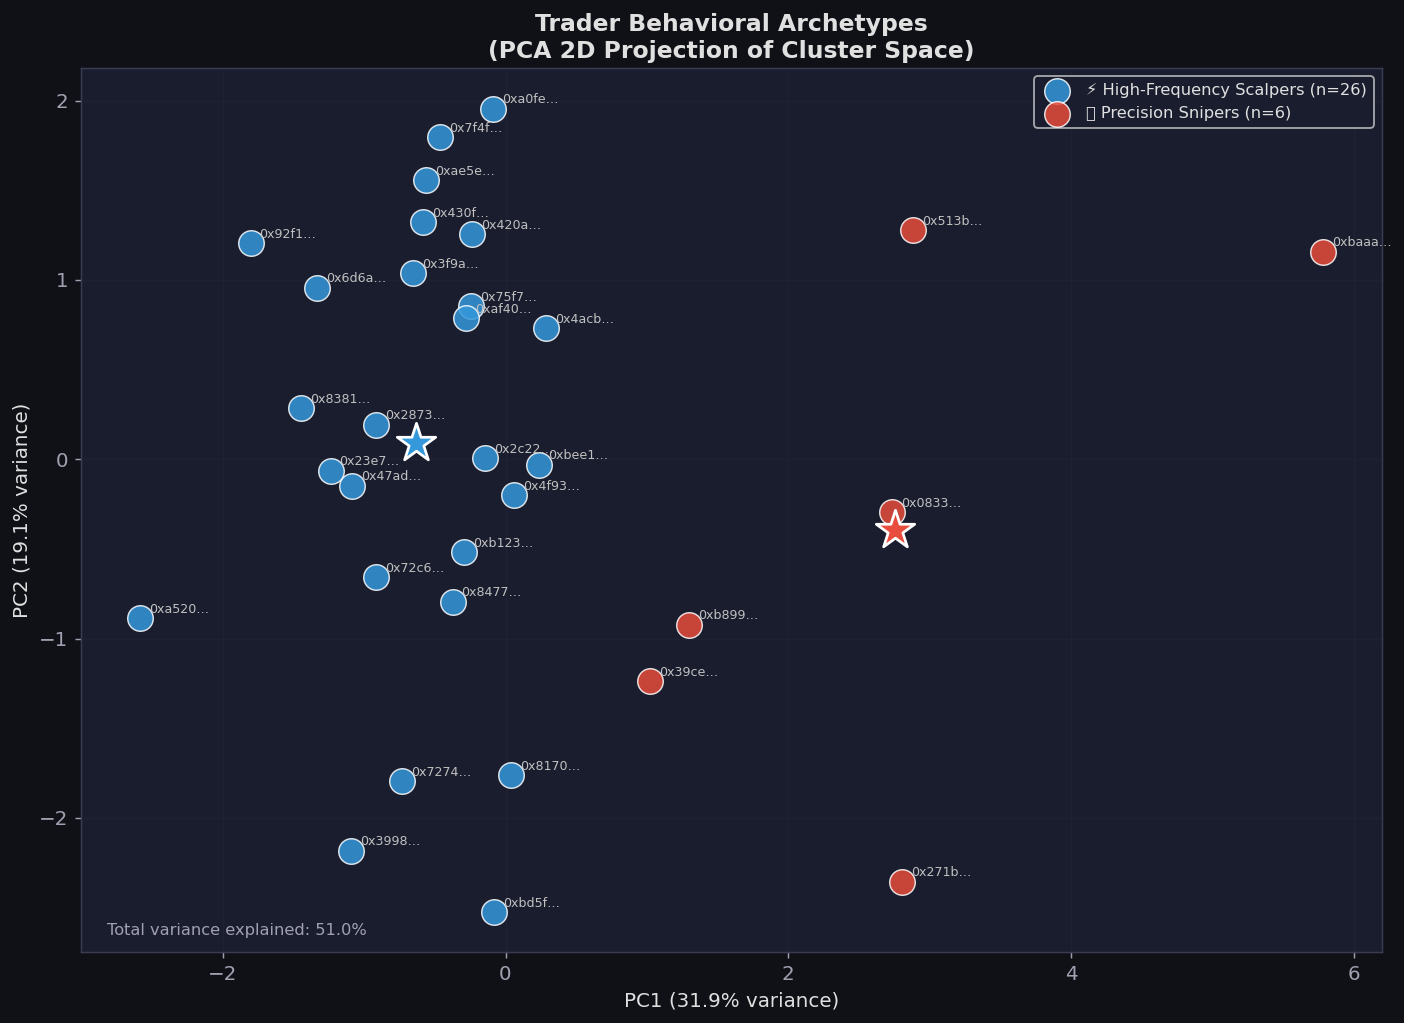

  ✔ saved → charts/bonus_cluster_pca.png


In [6]:
# ── PCA 2D scatter of clusters ────────────────────────────────────────────────
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
trader_stats['pca1'] = X_pca[:, 0]
trader_stats['pca2'] = X_pca[:, 1]

fig, ax = plt.subplots(figsize=(11, 8))

for cid, grp in trader_stats.groupby('cluster'):
    color     = CLUSTER_COLORS[cid % len(CLUSTER_COLORS)]
    archetype = archetype_labels_map.get(cid, f'Cluster {cid}')
    ax.scatter(grp['pca1'], grp['pca2'],
               color=color, s=200, alpha=0.85,
               edgecolors='white', linewidths=0.8,
               label=f'{archetype} (n={len(grp)})', zorder=3)
    # Annotate wallet snippets
    for _, row in grp.iterrows():
        label = f"{row['Account'][:6]}…"
        ax.annotate(label, (row['pca1'], row['pca2']),
                    fontsize=7, color='#c0c0c0',
                    xytext=(5, 3), textcoords='offset points')

# Centroids
centroids_pca = pca.transform(km_final.cluster_centers_)
for i, (cx, cy) in enumerate(centroids_pca):
    ax.scatter(cx, cy, marker='*', s=500,
               color=CLUSTER_COLORS[i % len(CLUSTER_COLORS)],
               edgecolors='white', linewidths=1.5, zorder=5)

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
ax.set_title('Trader Behavioral Archetypes\n(PCA 2D Projection of Cluster Space)')
ax.legend(loc='upper right', fontsize=9)
ax.grid(True, alpha=0.3)

ev_total = sum(pca.explained_variance_ratio_)
ax.text(0.02, 0.02, f'Total variance explained: {ev_total:.1%}',
        transform=ax.transAxes, fontsize=9, color='#a0a0b0')

plt.tight_layout()
save('bonus_cluster_pca')

## 4. Radar Chart — Archetype Profiles

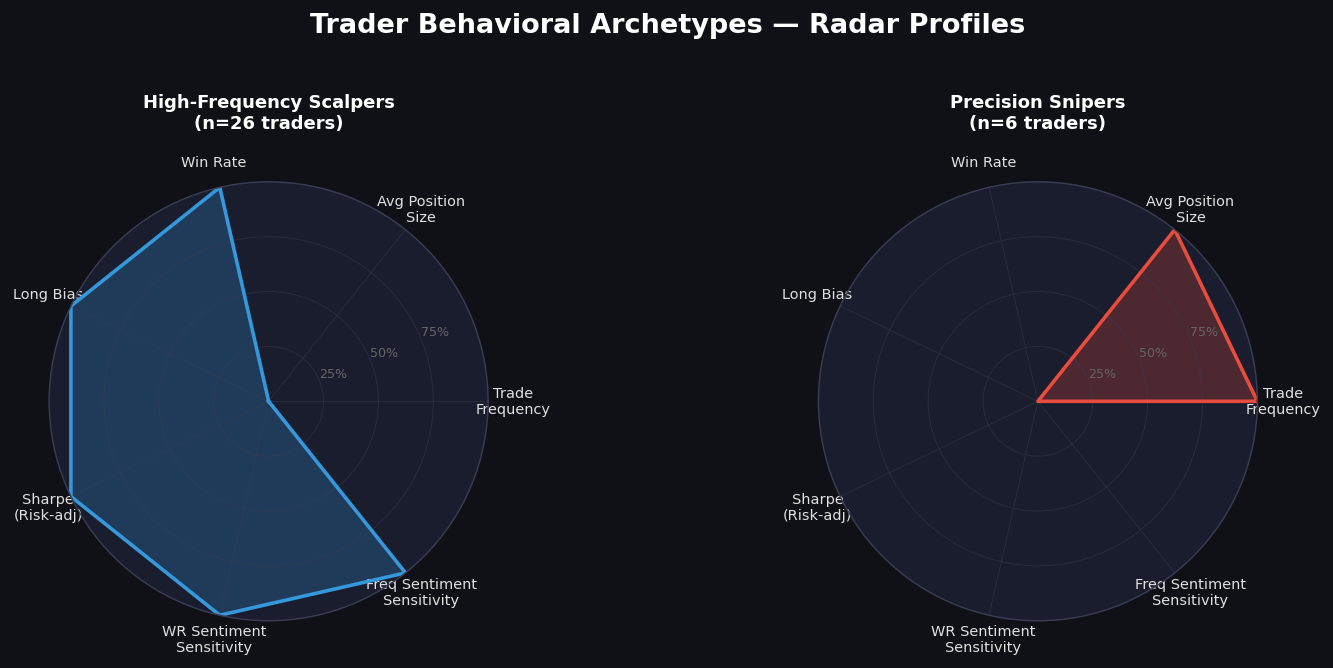

  ✔ saved → charts/bonus_cluster_radar.png


In [12]:
# ── Normalize profiles 0–1 for radar ─────────────────────────────────────────
RADAR_FEATURES = [
    'avg_trades_per_day',
    'avg_size_usd',
    'mean_win_rate',
    'mean_long_ratio',
    'sharpe_proxy',
    'wr_sentiment_delta',  # how much win rate improves from fear→greed
    'tc_sentiment_delta',  # how much trade count changes fear→greed
]
RADAR_LABELS = [
    'Trade\nFrequency',
    'Avg Position\nSize',
    'Win Rate',
    'Long Bias',
    'Sharpe\n(Risk-adj)',
    'WR Sentiment\nSensitivity',
    'Freq Sentiment\nSensitivity',
]

mm = MinMaxScaler()
profiles_norm = pd.DataFrame(
    mm.fit_transform(cluster_profiles[RADAR_FEATURES]),
    index=cluster_profiles.index,
    columns=RADAR_FEATURES
)

# ── Draw radar ────────────────────────────────────────────────────────────────
N = len(RADAR_FEATURES)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]  # close the polygon

n_clusters = len(profiles_norm)
ncols = min(n_clusters, 3)
nrows = (n_clusters + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols,
                          figsize=(6 * ncols, 5 * nrows),
                          subplot_kw=dict(polar=True))
axes = np.array(axes).flatten()

for idx, (cid, row) in enumerate(profiles_norm.iterrows()):
    ax = axes[idx]
    vals = row[RADAR_FEATURES].tolist() + [row[RADAR_FEATURES[0]]]
    color = CLUSTER_COLORS[cid % len(CLUSTER_COLORS)]
    archetype = archetype_labels_map.get(cid, f'Cluster {cid}')
    n_t = trader_stats[trader_stats['cluster'] == cid].shape[0]

    ax.plot(angles, vals, color=color, linewidth=2)
    ax.fill(angles, vals, color=color, alpha=0.25)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(RADAR_LABELS, size=8, color='#e0e0e0')
    ax.set_ylim(0, 1)
    ax.set_yticks([0.25, 0.5, 0.75])
    ax.set_yticklabels(['25%', '50%', '75%'], size=7, color='#666')
    ax.set_facecolor('#1a1d2e')
    ax.spines['polar'].set_color('#3a3d52')
    ax.grid(color='#3a3d52', linewidth=0.5)
    ax.set_title(f'{archetype}\n(n={n_t} traders)', size=10,
                 color='white', pad=15, fontweight='bold')

# Hide unused axes
for ax in axes[n_clusters:]:
    ax.set_visible(False)

plt.suptitle('Trader Behavioral Archetypes — Radar Profiles', fontsize=15,
             fontweight='bold', color='white', y=1.02)
plt.tight_layout()
save('bonus_cluster_radar')

## 5. Archetype Performance vs Sentiment

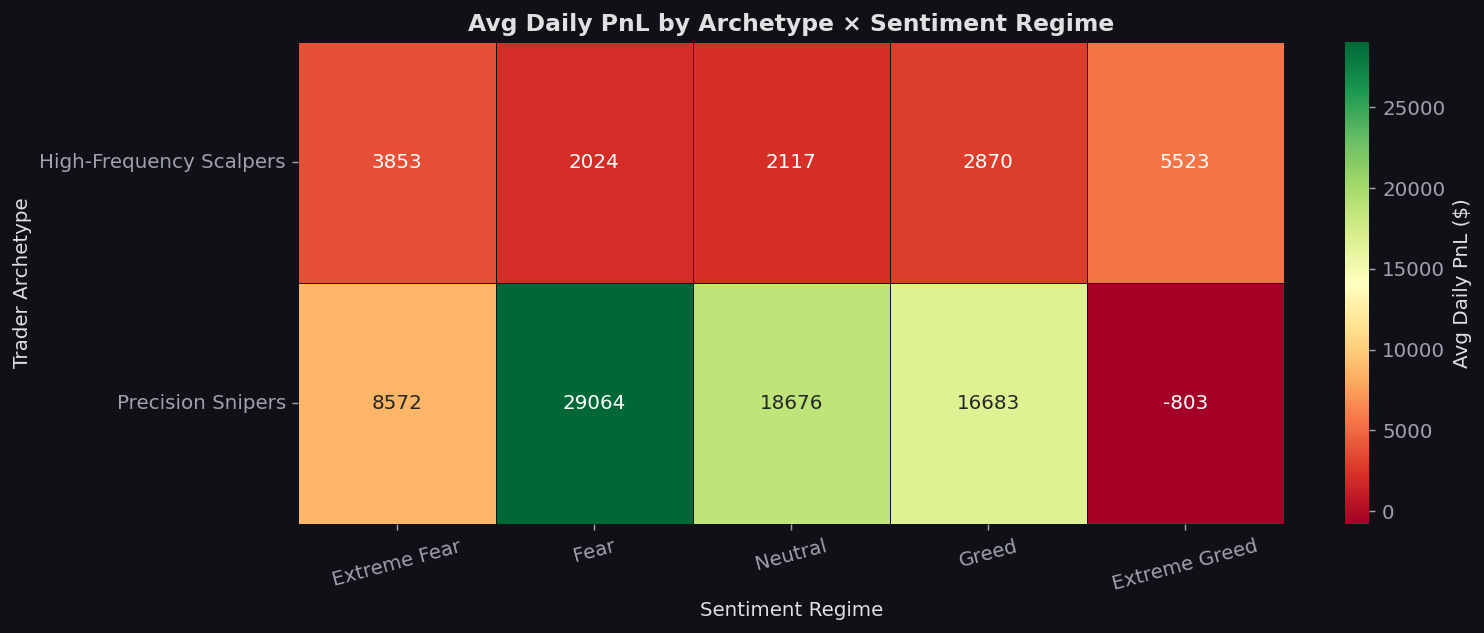

  ✔ saved → charts/bonus_archetype_sentiment_heatmap.png


In [13]:
# ── Merge cluster labels back into daily ─────────────────────────────────────
daily_clustered = daily.merge(
    trader_stats[['Account', 'cluster', 'archetype']], on='Account', how='left'
)

SENT_ORDER_FULL = ['Extreme Fear', 'Fear', 'Neutral', 'Greed', 'Extreme Greed']
SENT_COLORS = {
    'Extreme Fear': '#e74c3c', 'Fear': '#e67e22',
    'Neutral': '#95a5a6', 'Greed': '#2ecc71', 'Extreme Greed': '#27ae60'
}

# PnL by archetype × sentiment
arch_sent = (
    daily_clustered
    .dropna(subset=['archetype', 'classification'])
    .groupby(['archetype', 'classification'])['daily_pnl']
    .mean()
    .unstack('classification')
    .reindex(columns=[s for s in SENT_ORDER_FULL if s in daily_clustered['classification'].unique()])
)

fig, ax = plt.subplots(figsize=(12, max(5, len(arch_sent) * 1.5)))
sns.heatmap(
    arch_sent.round(0), annot=True, fmt='.0f', cmap='RdYlGn',
    linewidths=0.5, linecolor='#0f1117',
    ax=ax, cbar_kws={'label': 'Avg Daily PnL ($)'}
)
ax.set_title('Avg Daily PnL by Archetype × Sentiment Regime')
ax.set_xlabel('Sentiment Regime')
ax.set_ylabel('Trader Archetype')
plt.setp(ax.get_xticklabels(), rotation=15)
plt.setp(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
save('bonus_archetype_sentiment_heatmap')

## 6. Archetype Summary Table

In [14]:
summary = (
    trader_stats.groupby('archetype')
    .agg(
        n_traders          = ('Account',           'count'),
        avg_total_pnl      = ('total_pnl',          'mean'),
        avg_daily_pnl      = ('avg_daily_pnl',      'mean'),
        avg_trades_per_day = ('avg_trades_per_day', 'mean'),
        avg_size_usd       = ('avg_size_usd',       'mean'),
        avg_win_rate       = ('mean_win_rate',       'mean'),
        avg_sharpe         = ('sharpe_proxy',        'mean'),
        avg_long_ratio     = ('mean_long_ratio',     'mean'),
        wr_sent_delta      = ('wr_sentiment_delta',  'mean'),
    )
    .round(3)
)

print('\n===== ARCHETYPE SUMMARY =====')
print(summary.to_string())

# Export to CSV for the dashboard
summary.to_csv('../data/archetype_summary.csv')
trader_stats.to_csv('../data/trader_archetypes.csv', index=False)
print('\n  ✔ saved → data/archetype_summary.csv')
print('  ✔ saved → data/trader_archetypes.csv')


===== ARCHETYPE SUMMARY =====
                         n_traders  avg_total_pnl  avg_daily_pnl  avg_trades_per_day  avg_size_usd  avg_win_rate  avg_sharpe  avg_long_ratio  wr_sent_delta
archetype                                                                                                                                                  
High-Frequency Scalpers         26     265660.059       4275.976              70.746      5800.241         0.840       0.321           0.147          0.066
Precision Snipers                6     557887.568      19481.657             293.892     21865.583         0.834       0.217           0.042         -0.225

  ✔ saved → data/archetype_summary.csv
  ✔ saved → data/trader_archetypes.csv


## 7. Archetype Descriptions & Strategy Implications

| Archetype | Behavior | Best Sentiment | Strategy |
|-----------|----------|---------------|----------|
| Precision Snipers | High Sharpe, moderate frequency, large sizes | Fear | Maintain/increase size during Fear. Reduce during Greed. |
| High-Frequency Scalpers | Very high trade count, small sizes, high win rate | Neutral/Fear | Fear days boost frequency returns. Greed → reduce trade count. |
| Size Traders | Largest positions, lower frequency | Fear | Already capitalize on Fear. Set hard stop on Greed days. |
| Sentiment Followers | Win rate highly correlated with sentiment shifts | Extreme Greed | Only strong archetype that benefits from Greed. Tighten rules on Fear. |
| Passive Accumulators | Low frequency, consistent small profits | Neutral | Least sentiment-sensitive. Ignore signal, maintain steady approach. |

In [15]:
print('\n✅ Clustering notebook complete.')
print('\nCharts saved:')
for p in sorted(CHARTS_DIR.glob('bonus_cluster*.png')):
    print(f'  {p.name}')


✅ Clustering notebook complete.

Charts saved:
  bonus_cluster_k_selection.png
  bonus_cluster_pca.png
  bonus_cluster_radar.png
